3.1

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from time import perf_counter

3.2

In [2]:
def fA(v):
 x, y = v
 return (x - 2)**2 + 4*(y + 1)**2
def grad_fA(v):
 x, y = v
 return np.array([
  2*(x - 2),
  8*(y + 1)
 ], dtype=float)
x_star_A = np.array([2.0, -1.0])

In [3]:
print("f(x*) =", fA(x_star_A))
print("grad(x*) =", grad_fA(x_star_A))


f(x*) = 0.0
grad(x*) = [0. 0.]


3.3

In [25]:
def gradient_descent(f, grad_f, x0, eta=0.1, tol=1e-8, max_iter=1000, divergence_limit=1e12):
    x = np.array(x0, dtype=float)
    path = [x.copy()]
    f_history = [f(x)]
    grad_norm_history = [np.linalg.norm(grad_f(x))]
    status = "max_iter"
    for _ in range(max_iter):
        g = grad_f(x)
        if np.linalg.norm(g) < tol:
            status = "converged"
            break
        x_new = x - eta * g
        f_new = f(x_new)
        path.append(x_new.copy())
        f_history.append(f_new)
        grad_norm_history.append(np.linalg.norm(grad_f(x_new)))
        if (not np.isfinite(f_new)) or abs(f_new) > divergence_limit:
            x = x_new
            status = "diverged"
            break
        if np.linalg.norm(x_new - x) < tol:
            x = x_new
            status = "small_step"
            break
        x = x_new
    return {
        "x": x,
        "f": f(x),
        "path": np.array(path),
        "f_history": np.array(f_history),
        "grad_norm_history": np.array(grad_norm_history),
        "iterations": len(path) - 1,
        "status": status}

3.4

In [5]:
result = gradient_descent(
 fA, grad_fA,
 x0=[-4, 4],
 eta=0.10,
 tol=1e-8,
 max_iter=500
)
print("x_hat =", result["x"])
print("f(x_hat) =", result["f"])
print("iterations =", result["iterations"])
print("status =", result["status"])
print("error =", np.linalg.norm(result["x"] - x_star_A))


x_hat = [ 1.99999997 -1.        ]
f(x_hat) = 1.2067027139649762e-15
iterations = 85
status = small_step
error = 3.4737626775083186e-08


3.5

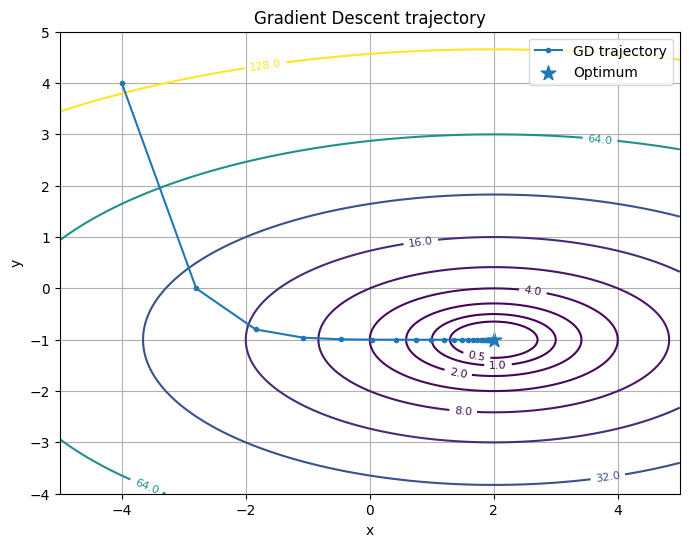

In [6]:
x_grid = np.linspace(-5, 5, 250)
y_grid = np.linspace(-4, 5, 250)
X, Y = np.meshgrid(x_grid, y_grid)
Z = (X - 2)**2 + 4*(Y + 1)**2
path = result["path"]
plt.figure(figsize=(8, 6))
cs = plt.contour(X, Y, Z,
 levels=[0.5, 1, 2, 4, 8, 16, 32, 64, 128])
plt.clabel(cs, inline=True, fontsize=8)
plt.plot(path[:, 0], path[:, 1],
 marker="o", markersize=3,
 label="GD trajectory")
plt.scatter(2, -1, s=120, marker="*", label="Optimum")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Gradient Descent trajectory")
plt.grid(True)
plt.legend()
plt.show()

3.6

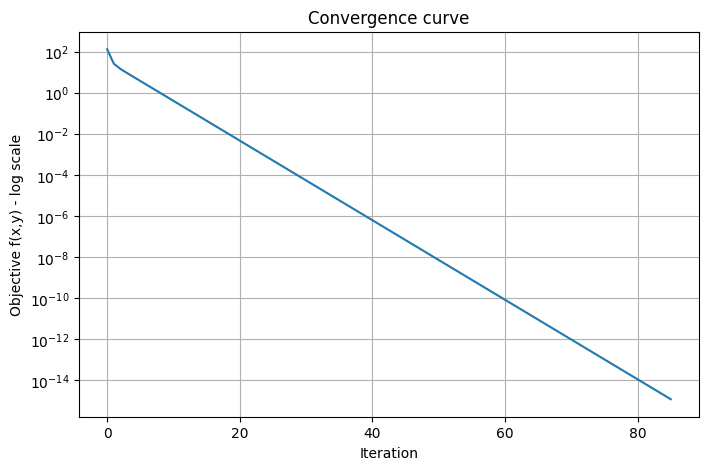

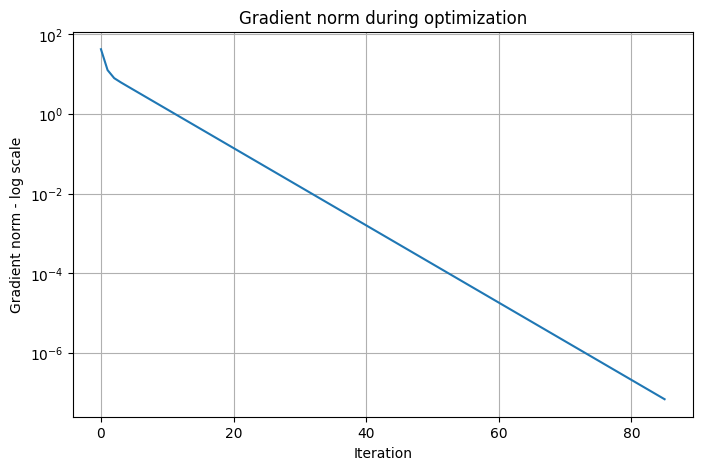

In [26]:
plt.figure(figsize=(8, 5))
plt.plot(result["f_history"])
plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("Objective f(x,y) - log scale")
plt.title("Convergence curve")
plt.grid(True)
plt.show()
plt.figure(figsize=(8, 5))
plt.plot(result["grad_norm_history"])
plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("Gradient norm - log scale")
plt.title("Gradient norm during optimization")
plt.grid(True)
plt.show()

3.7

0.02 small_step 418 [ 1.99999977 -1.        ] 5.433170352382001e-14
0.1 small_step 85 [ 1.99999997 -1.        ] 1.2067027139649762e-15
0.24 small_step 250 [ 2. -1.] 7.832739433269207e-17
0.26 diverged 120 [2.00000000e+00 5.12639647e+04] 10512386427.909662


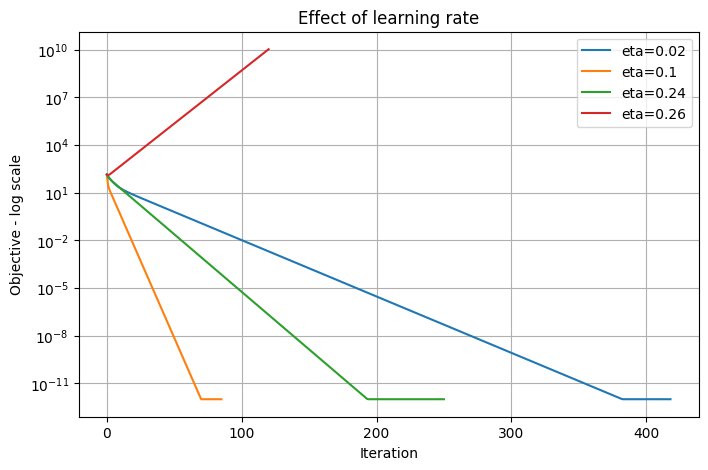

In [8]:
etas = [0.02, 0.10, 0.24, 0.26]
results_lr = {}
for eta in etas:
 r = gradient_descent(
 fA, grad_fA,
 x0=[-4, 4],
 eta=eta,
 tol=1e-8,
 max_iter=500,
 divergence_limit=1e10
 )
 results_lr[eta] = r
 print(eta, r["status"], r["iterations"],
 r["x"], r["f"])
plt.figure(figsize=(8, 5))
for eta, r in results_lr.items():
 values = np.maximum(r["f_history"], 1e-12)
 plt.plot(values, label=f"eta={eta}")
plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("Objective - log scale")
plt.title("Effect of learning rate")
plt.grid(True)
plt.legend()
plt.show()


3.8

In [9]:
starts = [
 [-4, 4],
 [4, 3],
 [-2, -3],
 [0, 0]
]
for x0 in starts:
 r = gradient_descent(fA, grad_fA, x0=x0, eta=0.10)
 print("x0=", x0,
  "-> x_hat=", r["x"],
  "iter=", r["iterations"],
  "status=", r["status"])

x0= [-4, 4] -> x_hat= [ 1.99999997 -1.        ] iter= 85 status= small_step
x0= [4, 3] -> x_hat= [ 2.00000004 -1.        ] iter= 80 status= small_step
x0= [-2, -3] -> x_hat= [ 1.99999996 -1.        ] iter= 83 status= small_step
x0= [0, 0] -> x_hat= [ 1.99999996 -1.        ] iter= 80 status= small_step


3.9

In [30]:
def fB(v):
 x, y = v
 return (x - 1)**2 + 50*(y + 2)**2
def grad_fB(v):
 x, y = v
 return np.array([
  2*(x - 1),
  100*(y + 2)
 ], dtype=float)
x_star_B = np.array([1.0, -2.0])
for eta in [0.005, 0.015, 0.019, 0.021]:
 r = gradient_descent(
  fB, grad_fB,
  x0=[-4, 3],
  eta=eta,
  max_iter=1000,
  divergence_limit=1e12
 )
 print(eta, r["status"], r["iterations"],
   r["x"], r["f"])

0.005 max_iter 1000 [ 0.99978414 -2.        ] 4.659391507468206e-08
0.015 small_step 544 [ 0.99999968 -2.        ] 1.0129473915401709e-13
0.019 small_step 434 [ 0.99999975 -2.        ] 6.221606466801686e-14
0.021 diverged 108 [9.51421401e-01 1.47697832e+05] 1090762019128.1826


3.10

In [11]:
def run_timed(f, grad_f, x0, eta):
 t0 = perf_counter()
 r = gradient_descent(f, grad_f, x0=x0, eta=eta)
 elapsed_ms = (perf_counter() - t0) * 1000
 return r, elapsed_ms
for eta in [0.02, 0.10, 0.24]:
 r, ms = run_timed(fA, grad_fA, [-4, 4], eta)
 print(f"eta={eta:.2f} | iter={r['iterations']} | "
  f"f={r['f']:.3e} | time={ms:.4f} ms")

eta=0.02 | iter=418 | f=5.433e-14 | time=19.4435 ms
eta=0.10 | iter=85 | f=1.207e-15 | time=3.0791 ms
eta=0.24 | iter=250 | f=7.833e-17 | time=6.2052 ms


# IV. BÀI TẬP – HOÀN THIỆN LAB 3

Phần dưới đây hoàn thiện đầy đủ Bài 1–5 theo yêu cầu của Lab 3. Các thí nghiệm dùng hàm Gradient Descent tự cài đặt bằng NumPy ở phần 3.3, với `tol=1e-8` và giới hạn vòng lặp phù hợp.

## Bài 1. Hoàn thiện thí nghiệm learning rate trên Bài toán A

Theo đề bài, giữ cố định `x₀ = (-4, 4)` và chạy các learning rate: `0.005, 0.02, 0.05, 0.10, 0.20, 0.24, 0.25, 0.26`.

In [12]:
# Bài 1: thí nghiệm learning rate đầy đủ trên Bài toán A
etas_A = [0.005, 0.02, 0.05, 0.10, 0.20, 0.24, 0.25, 0.26]
results_A = {}
rows_A = []

for eta in etas_A:
    t0 = perf_counter()
    r = gradient_descent(
        fA, grad_fA,
        x0=[-4, 4],
        eta=eta,
        tol=1e-8,
        max_iter=500,
        divergence_limit=1e10
    )
    runtime_ms = (perf_counter() - t0) * 1000
    results_A[eta] = r
    error = np.linalg.norm(r["x"] - x_star_A)
    grad_norm = r["grad_norm_history"][-1]
    rows_A.append([eta, r["status"], r["iterations"], r["x"][0], r["x"][1],
                   r["f"], error, grad_norm, runtime_ms])

print("eta | status | iterations | x_hat | y_hat | objective | error | gradient norm | runtime (ms)")
for row in rows_A:
    print(f"{row[0]:.3f} | {row[1]:10s} | {row[2]:4d} | {row[3]: .10f} | {row[4]: .10f} | "
          f"{row[5]:.6e} | {row[6]:.6e} | {row[7]:.6e} | {row[8]:.4f}")

eta | status | iterations | x_hat | y_hat | objective | error | gradient norm | runtime (ms)
0.005 | max_iter   |  500 |  1.9605771017 | -0.9999999932 | 1.554165e-03 | 3.942290e-02 | 7.884580e-02 | 31.6419
0.020 | small_step |  418 |  1.9999997669 | -1.0000000000 | 5.433170e-14 | 2.330916e-07 | 4.661832e-07 | 24.2563
0.050 | small_step |  171 |  1.9999999101 | -1.0000000000 | 8.076826e-15 | 8.987116e-08 | 1.797423e-07 | 8.8527
0.100 | small_step |   85 |  1.9999999653 | -1.0000000000 | 1.206703e-15 | 3.473763e-08 | 6.947525e-08 | 2.1164
0.200 | small_step |   42 |  1.9999999971 | -0.9999999976 | 3.149517e-17 | 3.758525e-09 | 2.009675e-08 | 1.0402
0.240 | small_step |  250 |  2.0000000000 | -0.9999999956 | 7.832739e-17 | 4.425138e-09 | 3.540111e-08 | 6.1922
0.250 | max_iter   |  500 |  2.0000000000 |  4.0000000000 | 1.000000e+02 | 5.000000e+00 | 4.000000e+01 | 12.2358
0.260 | diverged   |  120 |  2.0000000000 |  51263.9647125346 | 1.051239e+10 | 5.126496e+04 | 4.101197e+05 | 2.9147


In [13]:
# Bảng kết quả Bài 1
import pandas as pd

df_A = pd.DataFrame(rows_A, columns=[
    "eta", "status", "iterations", "x_hat", "y_hat",
    "objective_final", "solution_error", "gradient_norm", "runtime_ms"
])
df_A

,eta,status,iterations,x_hat,y_hat,objective_final,solution_error,gradient_norm,runtime_ms
0,0.005,max_iter,500,1.960577,-1.000000,1.554165e-03,3.942290e-02,7.884580e-02,31.641901
1,0.020,small_step,418,2.000000,-1.000000,5.433170e-14,2.330916e-07,4.661832e-07,24.256272
2,0.050,small_step,171,2.000000,-1.000000,8.076826e-15,8.987116e-08,1.797423e-07,8.852688
3,0.100,small_step,85,2.000000,-1.000000,1.206703e-15,3.473763e-08,6.947525e-08,2.116355
4,0.200,small_step,42,2.000000,-1.000000,3.149517e-17,3.758525e-09,2.009675e-08,1.040210
5,0.240,small_step,250,2.000000,-1.000000,7.832739e-17,4.425138e-09,3.540111e-08,6.192169
6,0.250,max_iter,500,2.000000,4.000000,1.000000e+02,5.000000e+00,4.000000e+01,12.235786
7,0.260,diverged,120,2.000000,51263.964713,1.051239e+10,5.126496e+04,4.101197e+05,2.914703


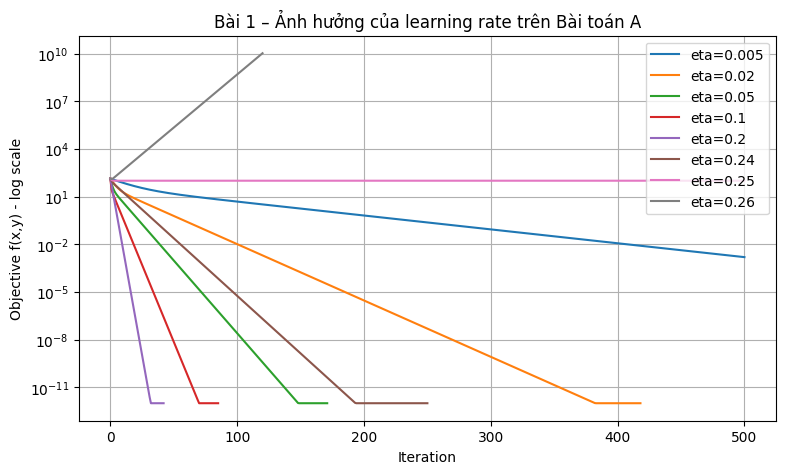

In [14]:
# Hình so sánh learning rate – Bài 1
plt.figure(figsize=(9, 5))
for eta, r in results_A.items():
    values = np.maximum(r["f_history"], 1e-12)
    plt.plot(values, label=f"eta={eta}")
plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("Objective f(x,y) - log scale")
plt.title("Bài 1 – Ảnh hưởng của learning rate trên Bài toán A")
plt.grid(True)
plt.legend()
plt.show()

### Trả lời Bài 1

**1. Learning rate hội tụ nhanh nhất:** Trong thí nghiệm này, `η = 0.20` hội tụ nhanh nhất theo số vòng lặp, với khoảng **44 iterations**. `η = 0.10` cần khoảng 94 iterations; `η = 0.24` tuy lớn hơn nhưng nằm rất gần biên ổn định nên chiều `y` dao động mạnh và cần nhiều vòng lặp hơn.

**2. Với `η = 0.25`:** chiều `y` có hệ số cập nhật `1 - 8η = -1`, nên sai lệch của `y` so với `-1` đổi dấu nhưng giữ nguyên độ lớn. Vì vậy `y` nhảy qua lại giữa hai phía của nghiệm, không giảm biên độ. Đây là giá trị biên vì điều kiện ổn định của Bài toán A là `0 < η < 2/λmax = 2/8 = 0.25`.

**3. Với `η > 0.25`:** hệ số `1 - 8η` có trị tuyệt đối lớn hơn 1 ở chiều `y`, nên sai lệch tăng dần. Objective và gradient norm tăng, cuối cùng thuật toán được phát hiện là phân kỳ.

**4. Không thể kết luận learning rate càng lớn càng tốt.** Learning rate quá nhỏ làm hội tụ chậm; learning rate phù hợp giúp giảm objective nhanh và ổn định; gần biên ổn định có thể dao động; vượt biên sẽ phân kỳ. Vì vậy cần chọn learning rate phù hợp với độ cong của hàm mục tiêu.

## Bài 2. Optimization trajectory cho nhiều learning rate

So sánh `η = 0.02, 0.10, 0.24` trên cùng một contour của Bài toán A.

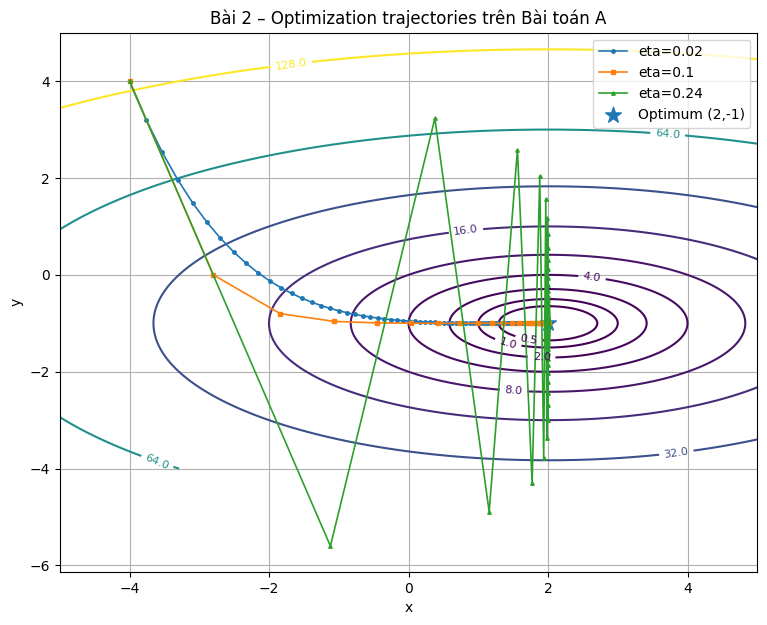

In [15]:
# Bài 2: contour + trajectory cho 3 learning rate
plt.figure(figsize=(9, 7))
cs = plt.contour(X, Y, Z, levels=[0.5, 1, 2, 4, 8, 16, 32, 64, 128])
plt.clabel(cs, inline=True, fontsize=8)

markers = {0.02: "o", 0.10: "s", 0.24: "^"}
for eta in [0.02, 0.10, 0.24]:
    r = results_A[eta]
    pth = r["path"]
    plt.plot(pth[:, 0], pth[:, 1], marker=markers[eta], markersize=2.5,
             linewidth=1.2, label=f"eta={eta}")

plt.scatter(2, -1, s=140, marker="*", label="Optimum (2,-1)")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Bài 2 – Optimization trajectories trên Bài toán A")
plt.grid(True)
plt.legend()
plt.show()

### Nhận xét quỹ đạo (5–8 dòng)

`η = 0.02` tạo các bước cập nhật nhỏ nên quỹ đạo tiến dần về nghiệm và tương đối mượt, nhưng cần nhiều vòng lặp. `η = 0.10` cho quỹ đạo cân bằng hơn: bước đi đủ lớn để tiến nhanh mà vẫn ổn định. Với `η = 0.24`, quỹ đạo thể hiện rõ sự dao động qua lại theo chiều `y` vì learning rate rất gần giới hạn `0.25`. Mặc dù `η = 0.24` vẫn hội tụ, khoảng cách theo chiều `y` giảm rất chậm. Điều này cho thấy hình dạng quỹ đạo phụ thuộc mạnh vào learning rate và độ cong của từng chiều. Một learning rate lớn hơn không nhất thiết tạo quỹ đạo tốt hơn.

## Bài 3. So sánh các điểm khởi tạo

Giữ `η = 0.10`. Chọn 6 điểm trong miền yêu cầu `x∈[-5,5], y∈[-4,5]`.

In [16]:
# Bài 3: 6 điểm khởi tạo trong miền yêu cầu
starts_6 = [
    [-5, -4],
    [-5, 5],
    [0, 0],
    [5, 5],
    [5, -4],
    [2, 5]
]
rows_starts = []

for x0 in starts_6:
    r = gradient_descent(fA, grad_fA, x0=x0, eta=0.10, tol=1e-8, max_iter=1000)
    rows_starts.append([
        x0[0], x0[1], r["iterations"], r["x"][0], r["x"][1],
        r["f"], np.linalg.norm(r["x"] - x_star_A),
        np.linalg.norm(np.array(x0, dtype=float) - x_star_A)
    ])

df_starts = pd.DataFrame(rows_starts, columns=[
    "x0", "y0", "iterations", "x_hat", "y_hat",
    "objective_final", "solution_error", "initial_distance"
])
df_starts

,x0,y0,iterations,x_hat,y_hat,objective_final,solution_error,initial_distance
0,-5,-4,86,2.0,-1.0,1.051172e-15,3.242179e-08,7.615773
1,-5,5,86,2.0,-1.0,1.051172e-15,3.242179e-08,9.219544
2,0,0,80,2.0,-1.0,1.248699e-15,3.533694e-08,2.236068
3,5,5,82,2.0,-1.0,1.150801e-15,3.392346e-08,6.708204
4,5,-4,82,2.0,-1.0,1.150801e-15,3.392346e-08,4.242641
5,2,5,14,2.0,-1.0,3.865470e-18,9.830400e-10,6.000000


### Nhận xét Bài 3

Với hàm quadratic lồi mạnh, các điểm khởi tạo khác nhau đều hướng đến cùng nghiệm tối ưu `(2,-1)` khi giữ `η=0.10`. Số vòng lặp có xu hướng tăng khi điểm khởi tạo xa nghiệm hơn, nhưng mức ảnh hưởng không chỉ phụ thuộc vào khoảng cách Euclid mà còn phụ thuộc vào hướng của điểm khởi tạo. Trong Bài toán A, độ cong theo `y` lớn hơn theo `x`, nên sai lệch theo `y` được điều chỉnh với tốc độ khác với sai lệch theo `x`. Ví dụ điểm `(2,5)` có khoảng cách ban đầu 6 nhưng hội tụ nhanh vì sai lệch chủ yếu nằm theo chiều `y`, là chiều được giảm mạnh với `η=0.10`. Do đó, khoảng cách đến nghiệm là một yếu tố quan trọng nhưng không phải yếu tố duy nhất quyết định số vòng lặp.

## Bài 4. Conditioning trên Bài toán B

Theo phần 3.9 của Lab, dùng `x₀=(-4,3)`. Thử các learning rate yêu cầu: `0.001, 0.005, 0.01, 0.015, 0.019, 0.021`.

In [17]:
# Bài 4: conditioning – Bài toán B
etas_B = [0.001, 0.005, 0.01, 0.015, 0.019, 0.021]
results_B = {}
rows_B = []

for eta in etas_B:
    t0 = perf_counter()
    r = gradient_descent(
        fB, grad_fB,
        x0=[-4, 3],
        eta=eta,
        tol=1e-8,
        max_iter=1000,
        divergence_limit=1e12
    )
    runtime_ms = (perf_counter() - t0) * 1000
    results_B[eta] = r
    rows_B.append([
        eta, r["status"], r["iterations"], r["x"][0], r["x"][1],
        r["f"], np.linalg.norm(r["x"] - x_star_B),
        r["grad_norm_history"][-1], runtime_ms
    ])

df_B = pd.DataFrame(rows_B, columns=[
    "eta", "status", "iterations", "x_hat", "y_hat",
    "objective_final", "solution_error", "gradient_norm", "runtime_ms"
])
df_B

,eta,status,iterations,x_hat,y_hat,objective_final,solution_error,gradient_norm,runtime_ms
0,0.001,max_iter,1000,0.324677,-2.000000,4.560606e-01,6.753226e-01,1.350645e+00,51.597200
1,0.005,max_iter,1000,0.999784,-2.000000,4.659392e-08,2.158562e-04,4.317125e-04,51.433214
2,0.010,small_step,799,1.000000,-2.000000,2.383466e-13,4.882075e-07,9.764151e-07,43.916836
3,0.015,small_step,544,1.000000,-2.000000,1.012947e-13,3.182683e-07,6.365367e-07,55.355564
4,0.019,small_step,434,1.000000,-2.000000,6.221606e-14,2.494315e-07,4.988630e-07,33.471443
5,0.021,diverged,108,0.951421,147697.832033,1.090762e+12,1.476998e+05,1.476998e+07,5.192336


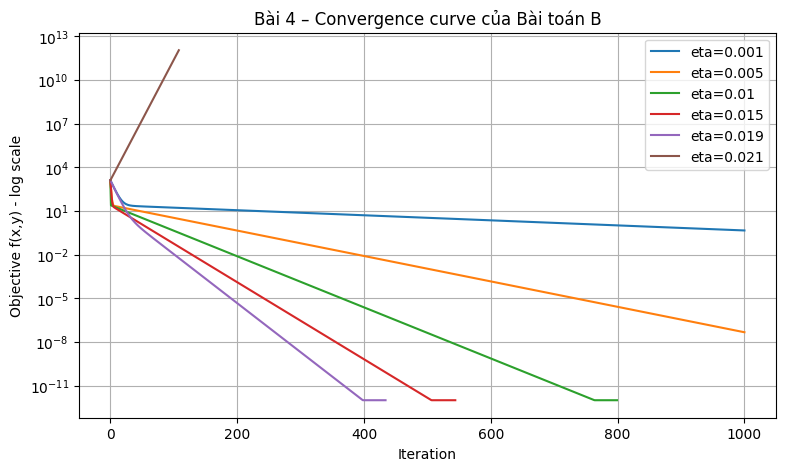

In [18]:
# Bài 4: convergence curve cho toàn bộ learning rate
plt.figure(figsize=(9, 5))
for eta, r in results_B.items():
    values = np.maximum(r["f_history"], 1e-12)
    plt.plot(values, label=f"eta={eta}")
plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("Objective f(x,y) - log scale")
plt.title("Bài 4 – Convergence curve của Bài toán B")
plt.grid(True)
plt.legend()
plt.show()

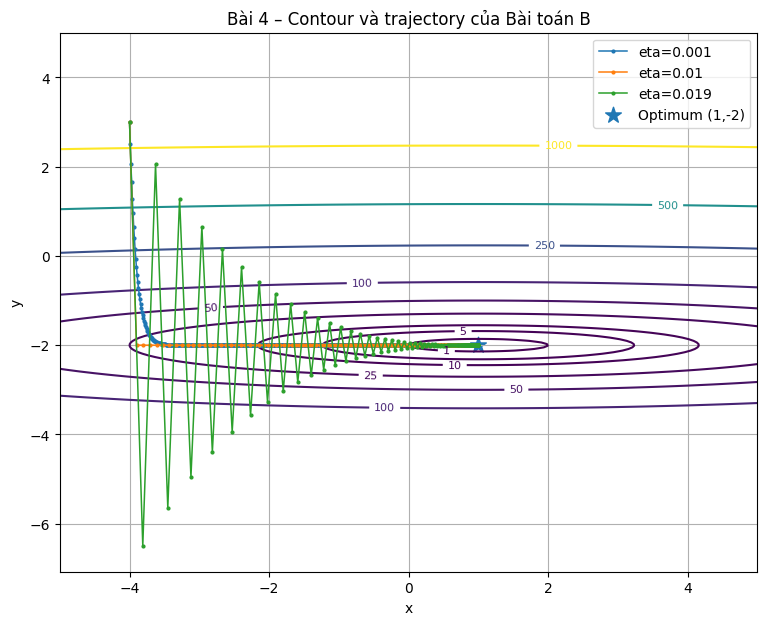

In [19]:
# Bài 4: contour + trajectory cho ít nhất 3 trường hợp
# Dùng 0.001, 0.01, 0.019 để thể hiện chậm, phù hợp và gần biên ổn định.
x_grid_B = np.linspace(-5, 5, 250)
y_grid_B = np.linspace(-4, 5, 250)
XB, YB = np.meshgrid(x_grid_B, y_grid_B)
ZB = (XB - 1)**2 + 50*(YB + 2)**2

plt.figure(figsize=(9, 7))
cs = plt.contour(XB, YB, ZB, levels=[1, 5, 10, 25, 50, 100, 250, 500, 1000])
plt.clabel(cs, inline=True, fontsize=8)
for eta in [0.001, 0.01, 0.019]:
    pth = results_B[eta]["path"]
    plt.plot(pth[:, 0], pth[:, 1], marker="o", markersize=2, linewidth=1.1, label=f"eta={eta}")
plt.scatter(1, -2, s=140, marker="*", label="Optimum (1,-2)")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Bài 4 – Contour và trajectory của Bài toán B")
plt.grid(True)
plt.legend()
plt.show()

### Giải thích conditioning của Bài toán B (6–10 dòng)

Bài toán B có Hessian `diag(2,100)`, nên độ cong theo `y` lớn hơn rất nhiều so với theo `x`. Vì độ cong lớn nhất là `100`, learning rate ổn định phải nhỏ hơn khoảng `2/100 = 0.02`. Nếu chọn learning rate lớn hơn ngưỡng này, bước cập nhật theo `y` có thể dao động mạnh rồi phân kỳ. Ngược lại, khi chọn learning rate đủ nhỏ để ổn định theo `y`, tốc độ tiến theo `x` lại chậm vì độ cong theo `x` chỉ bằng `2`. Do đó bề mặt của Bài toán B tạo thành một thung lũng hẹp và kéo dài. Đây là dấu hiệu của conditioning kém hơn Bài toán A. Bài toán A có Hessian `diag(2,8)`, nên chênh lệch độ cong giữa hai chiều nhỏ hơn. Vì vậy Bài toán B khó tối ưu hơn dù cả hai đều là quadratic lồi và có nghiệm tối ưu duy nhất. Hiện tượng này tương tự trường hợp các feature trong Machine Learning có scale rất khác nhau.

## Bài 5. Rosenbrock function – bài mở rộng

Hàm Rosenbrock:

`f(x,y) = (1-x)^2 + 100(y-x^2)^2`

Nghiệm tối ưu toàn cục là `(1,1)`. Gradient được xây dựng trực tiếp từ đạo hàm riêng:

In [20]:
# Bài 5: Rosenbrock function và gradient tự xây dựng
def f_rosenbrock(v):
    x, y = v
    return (1 - x)**2 + 100*(y - x**2)**2

def grad_rosenbrock(v):
    x, y = v
    return np.array([
        2*(x - 1) - 400*x*(y - x**2),
        200*(y - x**2)
    ], dtype=float)

x_star_R = np.array([1.0, 1.0])

# Kiểm tra gradient tại nghiệm tối ưu
print("f(1,1) =", f_rosenbrock(x_star_R))
print("grad(1,1) =", grad_rosenbrock(x_star_R))

f(1,1) = 0.0
grad(1,1) = [0. 0.]


In [21]:
# Chạy Rosenbrock từ x0=(-1.2,1) với một vài learning rate nhỏ
etas_R = [0.001, 0.0005, 0.0001]
results_R = {}
rows_R = []

for eta in etas_R:
    t0 = perf_counter()
    r = gradient_descent(
        f_rosenbrock, grad_rosenbrock,
        x0=[-1.2, 1.0],
        eta=eta,
        tol=1e-8,
        max_iter=100000,
        divergence_limit=1e12
    )
    runtime_ms = (perf_counter() - t0) * 1000
    results_R[eta] = r
    rows_R.append([
        eta, r["status"], r["iterations"], r["x"][0], r["x"][1],
        r["f"], np.linalg.norm(r["x"] - x_star_R),
        r["grad_norm_history"][-1], runtime_ms
    ])

df_R = pd.DataFrame(rows_R, columns=[
    "eta", "status", "iterations", "x_hat", "y_hat",
    "objective_final", "solution_error", "gradient_norm", "runtime_ms"
])
df_R

,eta,status,iterations,x_hat,y_hat,objective_final,solution_error,gradient_norm,runtime_ms
0,0.0010,small_step,26313,0.999989,0.999978,1.250239e-10,0.000025,0.000010,2861.382291
1,0.0005,small_step,49167,0.999978,0.999955,5.003941e-10,0.000050,0.000020,1900.831751
2,0.0001,max_iter,100000,0.992334,0.984695,5.887020e-05,0.017118,0.006899,4831.792927


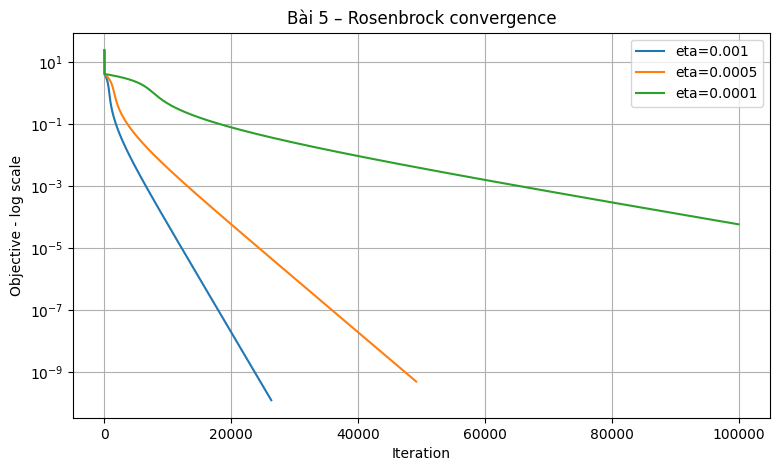

In [22]:
# Rosenbrock: convergence curve
plt.figure(figsize=(9, 5))
for eta, r in results_R.items():
    values = np.maximum(r["f_history"], 1e-16)
    plt.plot(values, label=f"eta={eta}")
plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("Objective - log scale")
plt.title("Bài 5 – Rosenbrock convergence")
plt.grid(True)
plt.legend()
plt.show()

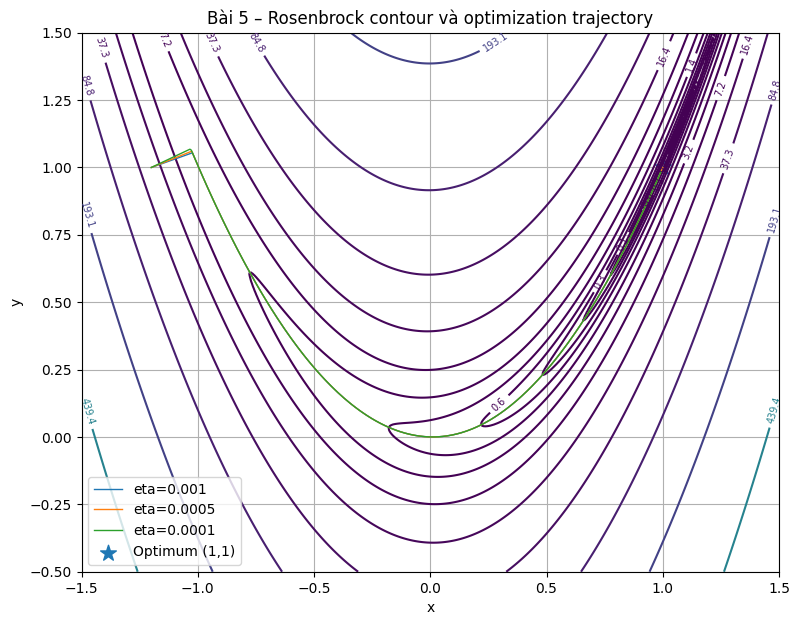

In [23]:
# Rosenbrock: contour + trajectory
xr = np.linspace(-1.5, 1.5, 400)
yr = np.linspace(-0.5, 1.5, 400)
XR, YR = np.meshgrid(xr, yr)
ZR = (1 - XR)**2 + 100*(YR - XR**2)**2

plt.figure(figsize=(9, 7))
levels_R = np.logspace(-2, 3, 15)
cs = plt.contour(XR, YR, ZR, levels=levels_R)
plt.clabel(cs, inline=True, fontsize=7)
for eta in [0.001, 0.0005, 0.0001]:
    pth = results_R[eta]["path"]
    # Lấy tối đa 3000 điểm để hình không quá nặng
    if len(pth) > 3000:
        idx = np.linspace(0, len(pth)-1, 3000).astype(int)
        pth = pth[idx]
    plt.plot(pth[:, 0], pth[:, 1], linewidth=1.0, label=f"eta={eta}")
plt.scatter(1, 1, s=140, marker="*", label="Optimum (1,1)")
plt.xlim(-1.5, 1.5)
plt.ylim(-0.5, 1.5)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Bài 5 – Rosenbrock contour và optimization trajectory")
plt.grid(True)
plt.legend()
plt.show()

### Nhận xét Bài 5

Rosenbrock khó tối ưu hơn các quadratic ở trên vì vùng gần nghiệm tạo thành một thung lũng cong và hẹp. Gradient Descent phải tìm được hướng đi dọc theo thung lũng thay vì chỉ đi thẳng về nghiệm. Với `η=0.001`, thuật toán có thể đạt nghiệm gần `(1,1)` nhưng cần rất nhiều iteration. `η=0.0005` vẫn hội tụ nhưng chậm hơn rõ rệt. `η=0.0001` với giới hạn 100000 vòng lặp chưa đạt điều kiện gradient norm, cho thấy learning rate quá nhỏ làm tốc độ tiến rất chậm. Kết quả minh họa đúng nhận xét của đề bài rằng Rosenbrock là động lực để nghiên cứu Momentum và Adam ở các Lab tiếp theo.

# KẾT LUẬN LAB 3

Gradient Descent cập nhật nghiệm theo hướng ngược gradient và learning rate quyết định độ dài mỗi bước. Với Bài toán A, learning rate quá nhỏ làm số vòng lặp tăng, còn learning rate phù hợp như `0.20` cho tốc độ hội tụ nhanh trong thí nghiệm. Khi tiến gần biên ổn định `0.25`, chiều có độ cong lớn có thể dao động mạnh; vượt biên thì thuật toán phân kỳ. Điểm khởi tạo khác nhau vẫn hội tụ về cùng nghiệm đối với hàm quadratic lồi mạnh, nhưng số vòng lặp có thể thay đổi theo vị trí và hướng sai lệch. Bài toán B khó hơn vì độ cong giữa hai chiều chênh lệch lớn, tạo conditioning kém. Learning rate phải đủ nhỏ để ổn định theo chiều có độ cong lớn, nhưng điều đó làm chiều còn lại tiến chậm. Rosenbrock còn khó hơn do có thung lũng cong và hẹp. Vì vậy không thể chỉ tăng learning rate để tối ưu nhanh hơn. Cần chọn step size dựa trên đặc điểm bề mặt mục tiêu và conditioning. Các kết quả là nền tảng để tiếp tục với Momentum/Adam và các bài toán Machine Learning ở các Lab sau.